<a href="https://colab.research.google.com/github/fdac25/MP2/blob/main/Vis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt



In [3]:
df = pd.read_csv("aberard_project_summary.csv", sep=";")
df.columns = ['project','commit','author','time','message']
df['Month'] = pd.to_datetime(df['time'], unit='s').dt.strftime('%Y-%m')
df.head()

,project,commit,author,time,message,Month
0,benfulcher_hctsa,000279bf51c5d92b79e6a3a7d470857d5bd473f5,Ben Fulcher <ben.d.fulcher@gmail.com>,1628146803,Support for custom annotations in TS_FeatureSu...,2021-08
1,benfulcher_hctsa,000bd184adca5a5a7db5e14df23a22b818536dc6,Ben Fulcher <ben.fulcher@gmail.com>,1378821153,A few fixes here and there. Changed DV_dynsys_...,2013-09
2,benfulcher_hctsa,0010375160c8434599743992b75b32818a358887,Ben Fulcher <ben.d.fulcher@gmail.com>,1440564091,Added fast implementation of visibility graph ...,2015-08
3,benfulcher_hctsa,00311d91f87cc13464c76e2885ea1b26215f9ffb,GitHub Action <action@github.com>,1738278259,ghrs: vc agg 01-30-2304-ED44 for benfulcher/hc...,2025-01
4,benfulcher_hctsa,004348617eef519b08c24802632e8d579def2878,Ben Fulcher <ben.fulcher@gmail.com>,1370535242,Made a bunch of changes in setting up the new ...,2013-06


In [11]:
all_monthly_counts = []

for prj in df["project"].dropna().unique():

    print(f"\nProcessing project: {prj}")

    df1 = df[df["project"] == prj]
    df2 = df1.groupby("Month").size().reset_index(name="Commits")
    monthly_counts = df2.copy()
    monthly_counts["time"] = pd.to_datetime(monthly_counts["Month"])

    print("Rows for project:", len(df1))
    print("Month column type:", df1["Month"].dtype)
    print(df1["Month"].head(10))
    print("Missing months:", df1["Month"].isna().sum())

    full_date_range = pd.DataFrame({
        "time": pd.date_range(
            start=monthly_counts["time"].min(),
            end=monthly_counts["time"].max(),
            freq="MS"
        )
    })

    monthly_counts = pd.merge(
        full_date_range, monthly_counts, on="time", how="left"
    ).fillna(0)

    monthly_counts["Month"] = monthly_counts["time"].dt.strftime("%Y-%m")
    monthly_counts["project"] = prj

    all_monthly_counts.append(monthly_counts)

# Combine all 10 projects into one DataFrame
monthly_counts_all = pd.concat(all_monthly_counts, ignore_index=True)

print(monthly_counts_all)


Processing project: benfulcher_hctsa
Rows for project: 3771
Month column type: str
0    2021-08
1    2013-09
2    2015-08
3    2025-01
4    2013-06
5    2024-06
6    2025-02
7    2024-08
8    2023-10
9    2025-10
Name: Month, dtype: str
Missing months: 0

Processing project: juliaopt_jump.jl
Rows for project: 12286
Month column type: str
3771    2019-08
3772    2023-02
3773    2023-02
3774    2014-04
3775    2023-05
3776    2022-02
3777    2017-02
3778    2018-10
3779    2018-10
3780    2022-06
Name: Month, dtype: str
Missing months: 0

Processing project: fredros_pypmc
Rows for project: 484
Month column type: str
16057    2024-09
16058    2019-06
16059    2023-07
16060    2014-12
16061    2024-09
16062    2014-08
16063    2024-09
16064    2014-03
16065    2016-08
16066    2014-04
Name: Month, dtype: str
Missing months: 0

Processing project: rpng_open_vins
Rows for project: 877
Month column type: str
16541    2023-04
16542    2021-07
16543    2020-12
16544    2021-11
16545    2023-03

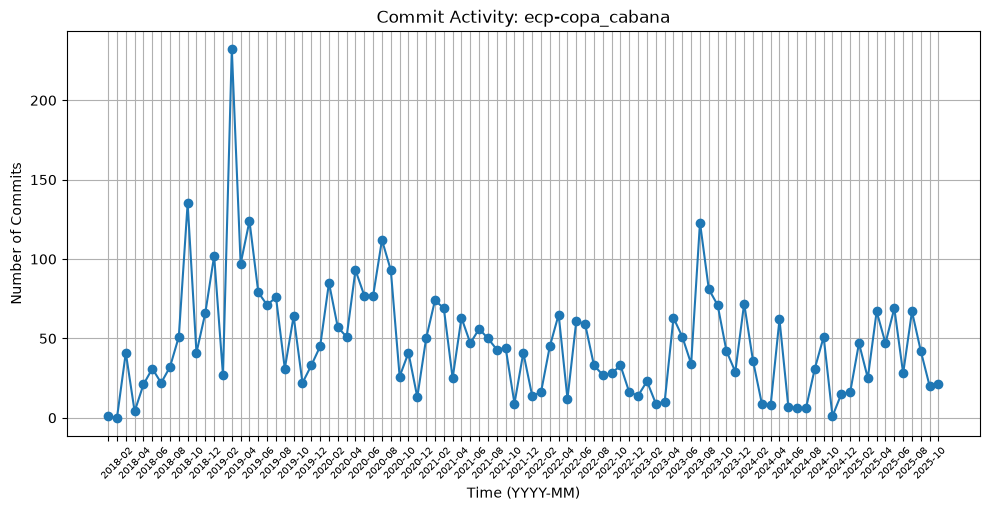

In [12]:
# Plot
import matplotlib.ticker as ticker

plt.figure(figsize=(10,5))
plt.plot(monthly_counts["Month"], monthly_counts["Commits"], marker="o", linestyle="-")
plt.xlabel("Time (YYYY-MM)")
plt.ylabel("Number of Commits")
plt.title("Commit Activity: "+prj)
plt.grid(True)
plt.tight_layout()
ax =  plt.gca()
for label in ax.xaxis.get_ticklabels()[::2]:
    label.set_visible(False)
plt.xticks(rotation=45, fontsize=7)
plt.savefig("aberard_timeseries_"+prj+".png", dpi=600)
plt.show()
plt.close()

# Identify the Longest Inactivity Gap

2022-02 to 2023-04

Add all that info to netid_project_stats.csv

In [14]:
# --------------------------------------------------
# 3. Find the longest inactivity gap for each project
# --------------------------------------------------

gap_commit_rows = []
before_themes = {}
after_themes = {}
gap_results = {}

for project, project_df in summary_df.groupby(PROJECT_COL):

    project_df = project_df.sort_values("commit_datetime").copy()

    # Count commits per calendar month
    monthly = (
        project_df.set_index("commit_datetime")
        .resample("MS")
        .size()
    )

    if monthly.empty:
        before_themes[project] = ""
        after_themes[project] = ""
        gap_results[project] = (pd.NaT, pd.NaT)
        continue

    # Complete the monthly timeline, including zero-commit months
    full_months = pd.date_range(
        start=monthly.index.min(),
        end=monthly.index.max(),
        freq="MS"
    )

    monthly = monthly.reindex(full_months, fill_value=0)

    # Find consecutive runs of zero-commit months
    zero_months = monthly.eq(0)
    runs = []
    run_start = None

    for month, is_zero in zero_months.items():
        if is_zero and run_start is None:
            run_start = month

        elif not is_zero and run_start is not None:
            runs.append(
                (run_start, month, (month - run_start).days)
            )
            run_start = None

    # Handle a gap continuing through the final recorded month
    if run_start is not None:
        next_month = monthly.index[-1] + pd.offsets.MonthBegin(1)
        runs.append(
            (run_start, next_month, (next_month - run_start).days)
        )

    # Select the longest inactivity gap, regardless of duration.
    # If tied, select the earliest gap.
    if not runs:
        before_themes[project] = ""
        after_themes[project] = ""
        gap_results[project] = (pd.NaT, pd.NaT)
        continue

    gap_start, gap_end, _ = max(
        runs,
        key=lambda gap: (gap[2], -gap[0].timestamp())
    )

    gap_results[project] = (gap_start, gap_end)

    # Select the 10 commits immediately before and after the gap.
    # gap_end is exclusive: it is the first month after the zero run.
    pre_commits = project_df[
        project_df["commit_datetime"] < gap_start
    ].tail(10)

    post_commits = project_df[
        project_df["commit_datetime"] >= gap_end
    ].head(10)

    before_themes[project] = top_two_themes(
        pre_commits[MESSAGE_COL]
    )

    after_themes[project] = top_two_themes(
        post_commits[MESSAGE_COL]
    )

    # Preserve the original summary columns and prepend pre/post
    original_columns = [
        col for col in summary_df.columns
        if col != "commit_datetime"
    ]

    for label, commits in [
        ("pre", pre_commits),
        ("post", post_commits)
    ]:
        if not commits.empty:
            output = commits[original_columns].copy()
            output.insert(0, "pre/post", label)
            gap_commit_rows.append(output)